# Geo-vektor — Klasifikasi Wilayah dari Titik (spatial join + agregasi + model)
**Kapan dipakai:** data berupa titik berkoordinat (rumah, toko, kejadian, pengguna) dan soal
minta label per **wilayah** (kelas harga, tingkat risiko, tingkat permintaan).

**Idenya:** titik dimasukkan ke poligon wilayah (`sjoin`), lalu diringkas per wilayah (jumlah
titik, rata-rata atribut). Ditambah feature lokasi: pusat wilayah (`centroid`), isi lingkaran
sekitar (`buffer`), isi blok besar (`dissolve`). Satu baris per wilayah → model klasifikasi.

**Langkah:**
1. Titik → GeoDataFrame meter. Wilayah dibaca dari **WKT** (bisa juga geojson/shapefile).
2. `sjoin` + ringkasan per wilayah + feature spasial.
3. Split per blok 100 km, model, submission.

**Data demo:** 6000 blok sensus California (lat/lon, pendapatan, umur rumah, dll.). Label
wilayah = kelas rata-rata harga rumah (murah / sedang / mahal). Kolom harga tidak dipakai
sebagai feature. Uji dipisah per blok 100 km supaya tetangga tidak bocor.

In [1]:
import geopandas as gpd
import h3
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from shapely.geometry import box
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import GroupShuffleSplit

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/tabular_extra/geo"   # GANTI saat lomba
POINTS_CSV = f"{DATA_FOLDER}/california_train.csv"
REGIONS_WKT_CSV = "wilayah_wkt.csv"   # demo: dibuat sendiri, saat lomba dari panitia

LON_COL = "Longitude"
LAT_COL = "Latitude"
VALUE_COL = "MedHouseVal"   # dipakai hanya untuk membuat label demo
CRS_METER = "EPSG:3310"     # California Albers (meter). Wilayah lain: cari kode EPSG UTM-nya
CELL_SIZE = 20_000          # sisi sel wilayah (meter)
BLOCK_SIZE = 100_000        # sisi blok besar untuk dissolve dan pemisah uji (meter)
RADIUS = 30_000             # radius buffer sekitar pusat sel (meter)
TEST_SIZE = 0.25
SEED = 42

## Baca titik

In [3]:
data = pd.read_csv(POINTS_CSV)
geometry = gpd.points_from_xy(data[LON_COL], data[LAT_COL])
points = gpd.GeoDataFrame(data, geometry=geometry, crs="EPSG:4326")
points = points.to_crs(CRS_METER)       # derajat → meter
print(points.shape)
points.head(3)

(6000, 11)


,id,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,geometry
0,3836,4.6197,21.0,3.701933,1.019329,1489.0,1.514751,34.05,-118.46,3.875,POINT (142176.229 -439465.973)
1,6408,3.8750,32.0,6.528090,1.101124,563.0,3.162921,33.86,-118.00,2.030,POINT (185083.408 -459742.636)
2,4840,6.8742,25.0,5.900480,1.038369,1913.0,2.293765,37.88,-122.53,4.131,POINT (-222205.538 -12194.321)


## Langkah 1 — wilayah: grid → simpan sebagai WKT → baca lagi
Soal biasanya memberi poligon wilayah dalam teks WKT. Di demo kita buat grid, simpan, lalu
baca ulang dengan `from_wkt` seperti file dari panitia.

In [4]:
left, bottom, right, top = points.total_bounds
cells = []
for cell_y in range(int(bottom), int(top), CELL_SIZE):
    for cell_x in range(int(left), int(right), CELL_SIZE):
        cells.append(box(cell_x, cell_y, cell_x + CELL_SIZE, cell_y + CELL_SIZE))
grid = pd.DataFrame()
grid["region_id"] = range(len(cells))
grid["wkt"] = gpd.GeoSeries(cells).to_wkt()
grid.to_csv(REGIONS_WKT_CSV, index=False)

wkt_table = pd.read_csv(REGIONS_WKT_CSV)
polygons = gpd.GeoSeries.from_wkt(wkt_table["wkt"])
regions = gpd.GeoDataFrame(wkt_table[["region_id"]], geometry=polygons, crs=CRS_METER)
print(len(regions), "sel grid")

2288 sel grid


## Langkah 2a — sjoin: titik masuk wilayah mana, lalu ringkas per wilayah
Wilayah tanpa titik dibuang.

In [5]:
points_in_region = gpd.sjoin(points, regions, predicate="within", how="inner")
per_region = points_in_region.groupby("region_id")
summary = pd.DataFrame()
summary["n_points"] = per_region["MedInc"].size()
summary["income"] = per_region["MedInc"].mean()
summary["income_std"] = per_region["MedInc"].std()
summary["house_age"] = per_region["HouseAge"].mean()
summary["rooms"] = per_region["AveRooms"].mean()
summary["population"] = per_region["Population"].mean()
summary["value"] = per_region[VALUE_COL].mean()
summary["income_std"] = summary["income_std"].fillna(0)

regions = regions[regions["region_id"].isin(summary.index)].copy()
for name in summary.columns:
    regions[name] = regions["region_id"].map(summary[name])
print(len(regions), "wilayah berisi titik")

441 wilayah berisi titik


## Langkah 2b — feature spasial: centroid, buffer, dissolve
- `centroid`: koordinat pusat sel.
- `buffer`: jumlah titik dan rata-rata pendapatan dalam radius sekitar pusat sel.
- `dissolve`: gabung sel jadi blok besar 100 km, jumlah titik per blok.

In [6]:
centers = regions.geometry.centroid
regions["center_x"] = centers.x
regions["center_y"] = centers.y

circles = gpd.GeoDataFrame(regions[["region_id"]], geometry=centers.buffer(RADIUS), crs=CRS_METER)
points_in_circle = gpd.sjoin(points, circles, predicate="within", how="inner")
per_circle = points_in_circle.groupby("region_id")
regions["points_in_radius"] = regions["region_id"].map(per_circle.size())
regions["income_in_radius"] = regions["region_id"].map(per_circle["MedInc"].mean())

block_column = (centers.x // BLOCK_SIZE).astype(int)
block_row = (centers.y // BLOCK_SIZE).astype(int)
regions["block"] = block_column.astype(str) + "_" + block_row.astype(str)
blocks = regions[["block", "n_points", "geometry"]].dissolve(by="block", aggfunc="sum")
regions["points_in_block"] = regions["block"].map(blocks["n_points"])
print(len(blocks), "blok setelah dissolve")

# Alternatif binning H3 (heksagon, tanpa grid sendiri): id sel H3 per titik, resolusi 5
# h3_cells = []
# for lat, lon in zip(data[LAT_COL], data[LON_COL]):
#     h3_cells.append(h3.latlng_to_cell(lat, lon, 5))
# points["h3"] = h3_cells
# print(points.groupby("h3").size().describe())

53 blok setelah dissolve


## Langkah 3a — label wilayah dan split per blok
Label demo = tertil harga rata-rata sel. Satu blok 100 km seluruhnya latih atau seluruhnya uji.

In [7]:
regions["label"] = pd.qcut(regions["value"], 3, labels=["murah", "sedang", "mahal"])
FEATURE_COLS = ["n_points", "income", "income_std", "house_age", "rooms", "population",
                "center_x", "center_y", "points_in_radius", "income_in_radius",
                "points_in_block"]
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
train_rows, test_rows = next(splitter.split(regions, groups=regions["block"]))
train = regions.iloc[train_rows]
test = regions.iloc[test_rows]
print("latih:", len(train), "wilayah | uji:", len(test), "wilayah")
print(train["label"].value_counts())

latih: 299 wilayah | uji: 142 wilayah
label
murah     107
mahal     104
sedang     88
Name: count, dtype: int64


## Langkah 3b — model + submission
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.
Untuk target angka per wilayah (mis. permintaan), pakai `LGBMRegressor`.

In [8]:
model = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=4, random_state=SEED)
# model = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1)

model.fit(train[FEATURE_COLS], train["label"])
predictions = model.predict(test[FEATURE_COLS])

submission = pd.DataFrame()
submission["region_id"] = test["region_id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,region_id,label
34,34,sedang
39,39,murah
77,77,mahal
80,80,murah
82,82,murah


## Cek dengan kunci jawaban (HAPUS saat lomba)

F1 macro: 0.6437
              precision    recall  f1-score   support

       mahal       0.61      0.81      0.70        43
       murah       0.67      0.78      0.72        40
      sedang       0.64      0.42      0.51        59

    accuracy                           0.64       142
   macro avg       0.64      0.67      0.64       142
weighted avg       0.64      0.64      0.63       142



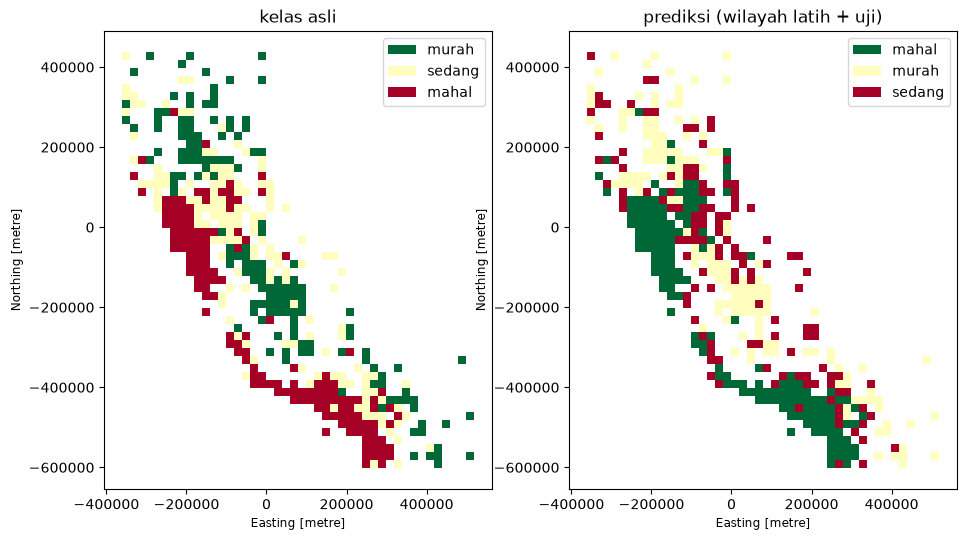

In [9]:
print("F1 macro:", round(f1_score(test["label"], predictions, average="macro"), 4))
print(classification_report(test["label"], predictions))

regions["prediction"] = model.predict(regions[FEATURE_COLS])
fig, ax = plt.subplots(1, 2, figsize=(11, 6))
regions.plot(column="label", cmap="RdYlGn_r", legend=True, ax=ax[0])
regions.plot(column="prediction", cmap="RdYlGn_r", legend=True, ax=ax[1])
ax[0].set_title("kelas asli")
ax[1].set_title("prediksi (wilayah latih + uji)")
plt.show()